<a href="https://colab.research.google.com/github/adamarsyadfaizin/Pembelajaran-Mesin_2026_3F/blob/main/JS07/JS07_Tugas.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import silhouette_score, davies_bouldin_score

DATA_PATH = "CC_Customer_Dataset.csv"
df = pd.read_csv(DATA_PATH)

print("Ukuran dataset:", df.shape)
display(df.head())
display(df.describe().T)
print("\nNilai kosong per kolom:")
display(df.isna().sum().to_frame("Jumlah nilai kosong"))

Ukuran dataset: (660, 7)


,Sl_No,Customer Key,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
0,1,87073,100000,2,1,1,0
1,2,38414,50000,3,0,10,9
2,3,17341,50000,7,1,3,4
3,4,40496,30000,5,1,1,4
4,5,47437,100000,6,0,12,3


,count,mean,std,min,25%,50%,75%,max
Sl_No,660.0,330.500000,190.669872,1.0,165.75,330.5,495.25,660.0
Customer Key,660.0,55141.443939,25627.772200,11265.0,33825.25,53874.5,77202.50,99843.0
Avg_Credit_Limit,660.0,34574.242424,37625.487804,3000.0,10000.00,18000.0,48000.00,200000.0
Total_Credit_Cards,660.0,4.706061,2.167835,1.0,3.00,5.0,6.00,10.0
Total_visits_bank,660.0,2.403030,1.631813,0.0,1.00,2.0,4.00,5.0
Total_visits_online,660.0,2.606061,2.935724,0.0,1.00,2.0,4.00,15.0
Total_calls_made,660.0,3.583333,2.865317,0.0,1.00,3.0,5.00,10.0


\nNilai kosong per kolom:


,Jumlah nilai kosong
Sl_No,0
Customer Key,0
Avg_Credit_Limit,0
Total_Credit_Cards,0
Total_visits_bank,0
Total_visits_online,0
Total_calls_made,0


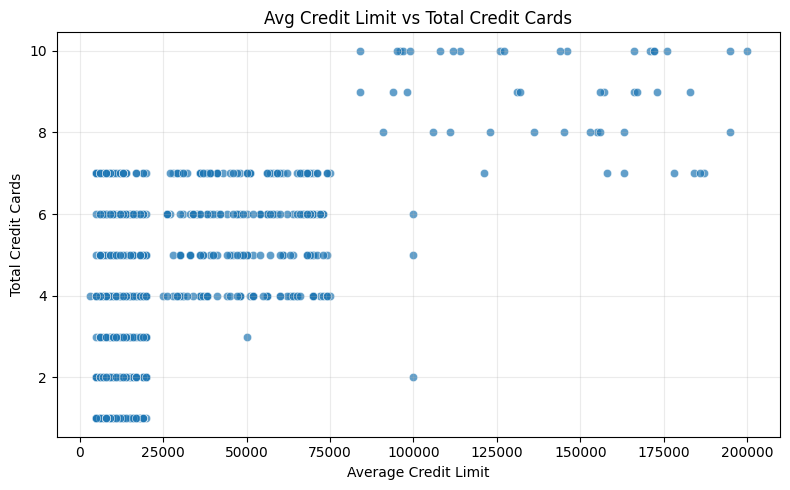

Korelasi Pearson: 0.609


In [ ]:
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df, x="Avg_Credit_Limit", y="Total_Credit_Cards", alpha=0.7)
plt.title("Avg Credit Limit vs Total Credit Cards")
plt.xlabel("Average Credit Limit")
plt.ylabel("Total Credit Cards")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

corr = df[["Avg_Credit_Limit", "Total_Credit_Cards"]].corr().iloc[0, 1]
print(f"Korelasi Pearson: {corr:.3f}")

**Analisis:** membentuk kelompok/pola terpisah. Nilai korelasi Pearson yang mendekati `+1` menunjukkan hubungan linier positif yang kuat,

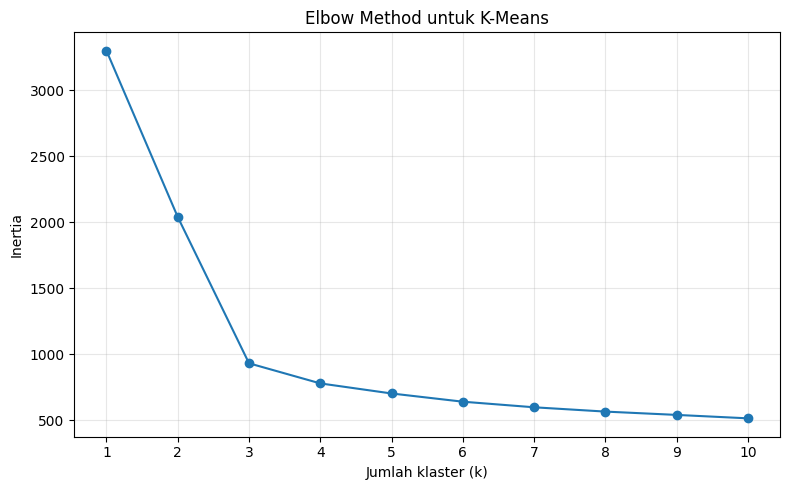

,k,inertia
0,1,3300.000
1,2,2040.990
2,3,933.044
3,4,780.774
4,5,704.476
5,6,642.274
6,7,599.925
7,8,567.328
8,9,542.253
9,10,516.242


In [ ]:
features = [
    "Avg_Credit_Limit",
    "Total_Credit_Cards",
    "Total_visits_bank",
    "Total_visits_online",
    "Total_calls_made"
]

X = df[features].copy()
if X.isna().any().any():
    X = X.fillna(X.median(numeric_only=True))

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k_values = range(1, 11)
inertias = []
for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(k_values), inertias, marker="o")
plt.xticks(list(k_values))
plt.xlabel("Jumlah klaster (k)")
plt.ylabel("Inertia")
plt.title("Elbow Method untuk K-Means")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

display(pd.DataFrame({"k": list(k_values), "inertia": inertias}).round(3))

In [ ]:
best_k = 3
kameans = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df["KMeans_Cluster"] = kameans.fit_predict(X_scaled)

print(f"Jumlah klaster yang dipilih: k = {best_k}")
print("Jumlah pelanggan pada setiap klaster:")
display(df["KMeans_Cluster"].value_counts().sort_index().to_frame("Jumlah pelanggan"))

Jumlah klaster yang dipilih: k = 3
Jumlah pelanggan pada setiap klaster:


,Jumlah pelanggan
KMeans_Cluster,
0,386
1,50
2,224


**Alasan pemilihan `k = 3`:** pilih titik pada grafik ketika penurunan inertia yang tajam mulai berubah menjadi penurunan yang lebih landai. Jika grafik hasil eksekusi menunjukkan perubahan paling jelas di sekitar `k = 3`, maka tiga klaster memberi keseimbangan antara pengurangan inertia dan kompleksitas model. Elbow method merupakan heuristik, jadi pilihan ini sebaiknya juga dipertimbangkan bersama interpretasi klaster dan metrik evaluasi.

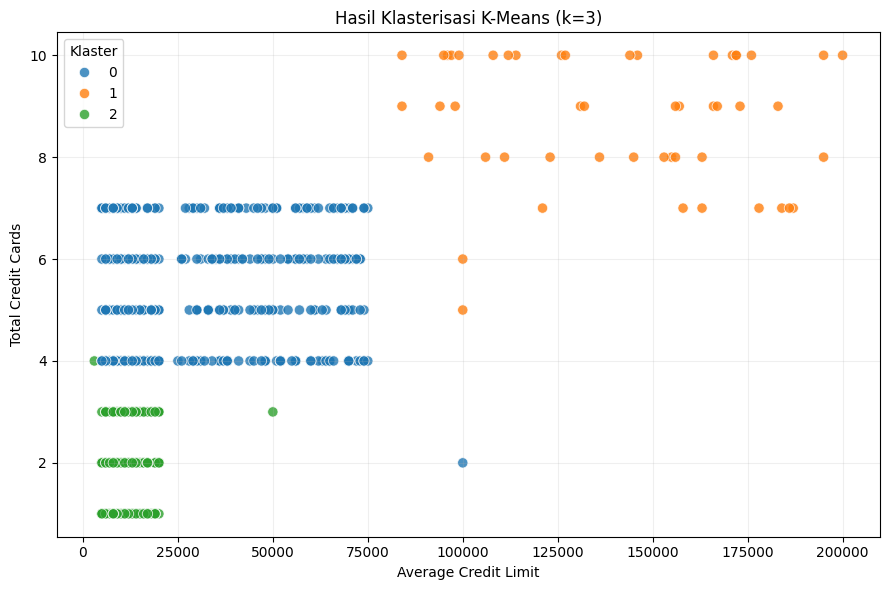

,Avg_Credit_Limit,Total_Credit_Cards,Total_visits_bank,Total_visits_online,Total_calls_made
KMeans_Cluster,,,,,
0,33782.38,5.52,3.49,0.98,2.00
1,141040.00,8.74,0.60,10.90,1.08
2,12174.11,2.41,0.93,3.55,6.87


In [ ]:
plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=df,
    x="Avg_Credit_Limit",
    y="Total_Credit_Cards",
    hue="KMeans_Cluster",
    palette="tab10",
    alpha=0.8,
    s=55
)
plt.title(f"Hasil Klasterisasi K-Means (k={best_k})")
plt.xlabel("Average Credit Limit")
plt.ylabel("Total Credit Cards")
plt.legend(title="Klaster")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

display(df.groupby("KMeans_Cluster")[features].mean().round(2))

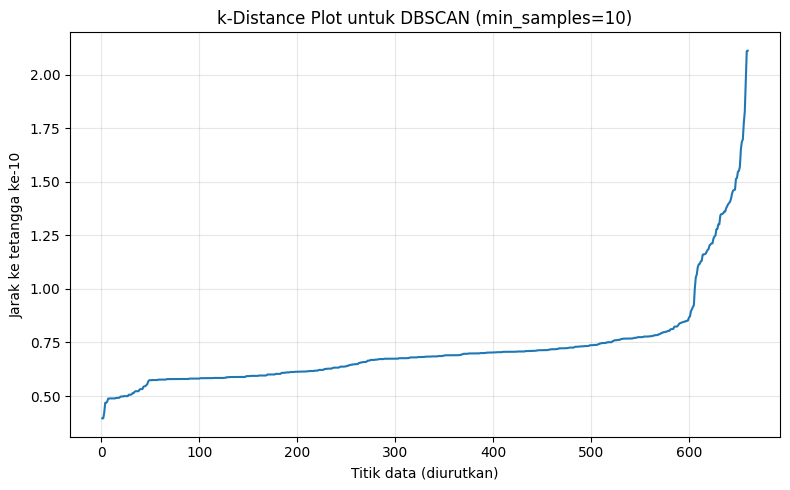

In [ ]:
min_samples = 10
neighbors = NearestNeighbors(n_neighbors=min_samples)
neighbors.fit(X_scaled)
distances, _ = neighbors.kneighbors(X_scaled)
k_distances = np.sort(distances[:, -1])

plt.figure(figsize=(8, 5))
plt.plot(np.arange(1, len(k_distances) + 1), k_distances)
plt.xlabel("Titik data (diurutkan)")
plt.ylabel(f"Jarak ke tetangga ke-{min_samples}")
plt.title(f"k-Distance Plot untuk DBSCAN (min_samples={min_samples})")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Pada *k-distance plot*, `eps` biasanya dipilih di sekitar bagian kurva yang mulai menanjak tajam (*knee*). Nilai tersebut adalah panduan, bukan jawaban otomatis. Nilai `eps` yang terlalu kecil dapat menganggap banyak titik sebagai noise atau hanya membentuk satu klaster; nilai terlalu besar dapat menggabungkan kelompok yang seharusnya terpisah.

In [ ]:
eps_value = 1.1
dbscan = DBSCAN(eps=eps_value, min_samples=min_samples)
df["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)

labels = df["DBSCAN_Cluster"].to_numpy()
n_clusters = len(set(labels) - {-1})
n_noise = int(np.sum(labels == -1))
noise_pct = 100 * n_noise / len(labels)

print(f"Parameter DBSCAN: eps={eps_value}, min_samples={min_samples}")
print(f"Jumlah klaster (di luar noise): {n_clusters}")
print(f"Jumlah noise: {n_noise} ({noise_pct:.2f}%)")
display(df["DBSCAN_Cluster"].value_counts().sort_index().to_frame("Jumlah data; -1 berarti noise"))

Parameter DBSCAN: eps=1.1, min_samples=10
Jumlah klaster (di luar noise): 3
Jumlah noise: 33 (5.00%)


,Jumlah data; -1 berarti noise
DBSCAN_Cluster,
-1,33
0,608
1,10
2,9


In [ ]:
labels = df["DBSCAN_Cluster"].to_numpy()
non_noise_mask = labels != -1
labels_non_noise = labels[non_noise_mask]
X_non_noise = X_scaled[non_noise_mask]
unique_non_noise = np.unique(labels_non_noise)

print(f"Data non-noise: {non_noise_mask.sum()} dari {len(labels)}")
print(f"Jumlah klaster non-noise: {len(unique_non_noise)}")
print(f"Proporsi noise: {(~non_noise_mask).mean() * 100:.2f}%")

if len(unique_non_noise) >= 2 and len(labels_non_noise) > len(unique_non_noise):
    sil = silhouette_score(X_non_noise, labels_non_noise)
    dbi = davies_bouldin_score(X_non_noise, labels_non_noise)
    print(f"Silhouette Score (non-noise): {sil:.4f}")
    print(f"Davies–Bouldin Index / DBI (non-noise): {dbi:.4f}")
else:
    sil, dbi = np.nan, np.nan
    print("Silhouette Score dan DBI tidak dapat dihitung dengan andal: diperlukan setidaknya dua klaster non-noise.")

metrics = pd.DataFrame({
    "Metrik": ["Silhouette Score (non-noise)", "Davies–Bouldin Index / DBI (non-noise)"],
    "Nilai": [sil, dbi]
})
display(metrics.round(4))

Data non-noise: 627 dari 660
Jumlah klaster non-noise: 3
Proporsi noise: 5.00%
Silhouette Score (non-noise): 0.5522
Davies–Bouldin Index / DBI (non-noise): 0.9102


,Metrik,Nilai
0,Silhouette Score (non-noise),0.5522
1,Davies–Bouldin Index / DBI (non-noise),0.9102


## Kesimpulan

1. Scatterplot dan korelasi Pearson membantu menilai apakah hubungan `Avg_Credit_Limit` dan `Total_Credit_Cards` tampak linier.
2. Nilai `k` K-Means dipilih dari titik elbow pada grafik inertia; pada analisis ini digunakan kandidat `k=3`.
3. Plot K-Means menunjukkan pembagian pelanggan berdasarkan lima fitur yang distandardisasi.
4. DBSCAN menggunakan seluruh lima fitur relevan, bukan kolom ID.
5. Untuk DBSCAN, *k-distance plot* lebih tepat untuk membantu memilih `eps` daripada elbow method untuk jumlah `k`.
6. Silhouette Score dan DBI dilaporkan untuk klaster non-noise, bersama proporsi noise supaya hasil evaluasi tidak ditafsirkan tanpa konteks.